# BÀI 1: PHÂN LỚP DỮ LIỆU IRIS

## 1. Import thư viện và in thông tin sinh viên

In [14]:
print("NguyenDucTinh - 6451071077")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

NguyenDucTinh - 6451071077


## Câu a: Đọc bộ dữ liệu Iris từ sklearn

In [15]:
print("NguyenDucTinh - 6451071077")

iris = load_iris()

X = iris.data
Y = iris.target

print("Đọc dữ liệu Iris thành công!")
print("Tên các loài hoa:", iris.target_names)

NguyenDucTinh - 6451071077
Đọc dữ liệu Iris thành công!
Tên các loài hoa: ['setosa' 'versicolor' 'virginica']


## Câu b: Khảo sát bộ dữ liệu Iris

In [16]:
print("NguyenDucTinh - 6451071077")

# In tên các thuộc tính
print("Tên các thuộc tính:")
print(iris.feature_names)

# In thuộc tính phân lớp
print("\nCác lớp phân loại:")
print(iris.target_names)

# In số lượng mẫu và thuộc tính
print("\nKích thước dữ liệu:", X.shape)
print("Số lượng mẫu:", X.shape[0])
print("Số lượng thuộc tính:", X.shape[1])
print("Số lượng nhãn:", Y.shape[0])

# In 5 mẫu dữ liệu đầu tiên
print("\n5 mẫu dữ liệu đầu tiên:")
print(X[:5])

print("\n5 nhãn tương ứng:")
print(Y[:5])

# Tạo DataFrame và thống kê
df = pd.DataFrame(X, columns=iris.feature_names)
print("\nThống kê dữ liệu:")
display(df.describe())

NguyenDucTinh - 6451071077
Tên các thuộc tính:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Các lớp phân loại:
['setosa' 'versicolor' 'virginica']

Kích thước dữ liệu: (150, 4)
Số lượng mẫu: 150
Số lượng thuộc tính: 4
Số lượng nhãn: 150

5 mẫu dữ liệu đầu tiên:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

5 nhãn tương ứng:
[0 0 0 0 0]

Thống kê dữ liệu:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## Câu c: Chuẩn hóa dữ liệu về đoạn [0, 1]

In [17]:
print("NguyenDucTinh - 6451071077")

# Chia mỗi giá trị cho giá trị lớn nhất của cột tương ứng
X = X / X.max(axis=0)

print("5 mẫu dữ liệu sau chuẩn hóa:")
print(X[:5])

print("\nGiá trị lớn nhất của từng thuộc tính:")
print(X.max(axis=0))

NguyenDucTinh - 6451071077
5 mẫu dữ liệu sau chuẩn hóa:
[[0.64556962 0.79545455 0.20289855 0.08      ]
 [0.62025316 0.68181818 0.20289855 0.08      ]
 [0.59493671 0.72727273 0.1884058  0.08      ]
 [0.58227848 0.70454545 0.2173913  0.08      ]
 [0.63291139 0.81818182 0.20289855 0.08      ]]

Giá trị lớn nhất của từng thuộc tính:
[1. 1. 1. 1.]


## Câu d: Chia dữ liệu Train/Test theo tỷ lệ 8:2

In [18]:
print("NguyenDucTinh - 6451071077")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("Số mẫu tập Train:", X_train.shape[0])
print("Số mẫu tập Test:", X_test.shape[0])

NguyenDucTinh - 6451071077
Số mẫu tập Train: 120
Số mẫu tập Test: 30


## Hàm đánh giá mô hình dùng chung

In [19]:
print("NguyenDucTinh - 6451071077")

def danh_gia_mo_hinh(model_name, y_test, y_pred):
    print("\n" + "=" * 50)
    print("ĐÁNH GIÁ MÔ HÌNH:", model_name)
    print("=" * 50)

    # Tính Accuracy
    accuracy = accuracy_score(y_test, y_pred)
    print("\nAccuracy:", accuracy)

    # In Precision, Recall, F1-score
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names,
        zero_division=0
    ))

    # Tính và hiển thị Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    print("\nConfusion Matrix:")
    print(cm)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names
    )
    plt.title("Confusion Matrix - " + model_name)
    plt.xlabel("Nhãn dự đoán")
    plt.ylabel("Nhãn thực tế")
    plt.tight_layout()
    plt.show()

    return accuracy

NguyenDucTinh - 6451071077


## Câu e: Phân lớp bằng Decision Tree

NguyenDucTinh - 6451071077

ĐÁNH GIÁ MÔ HÌNH: Decision Tree

Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


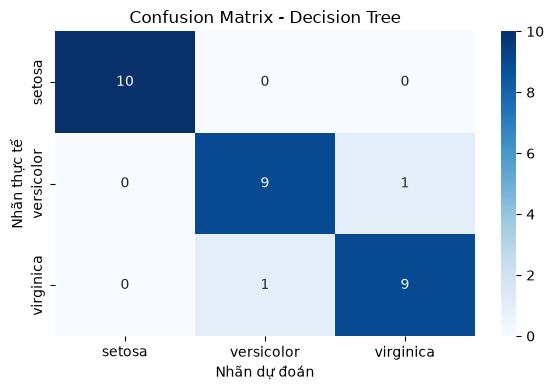

In [20]:
print("NguyenDucTinh - 6451071077")

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

acc_dt = danh_gia_mo_hinh("Decision Tree", y_test, y_pred_dt)

## Câu f: Phân lớp bằng Naïve Bayes

NguyenDucTinh - 6451071077

ĐÁNH GIÁ MÔ HÌNH: Naive Bayes

Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


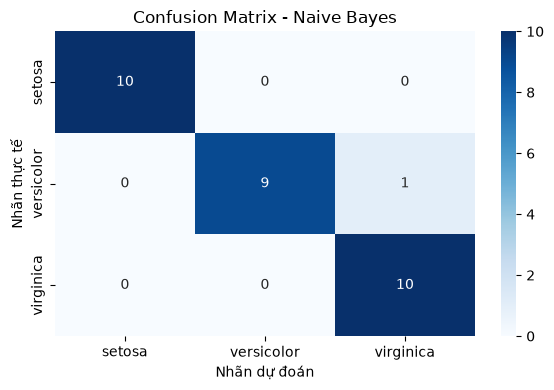

In [21]:
print("NguyenDucTinh - 6451071077")

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

acc_nb = danh_gia_mo_hinh("Naive Bayes", y_test, y_pred_nb)

## Câu g: Phân lớp bằng K-Nearest Neighbors

NguyenDucTinh - 6451071077

ĐÁNH GIÁ MÔ HÌNH: K Nearest Neighbors

Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


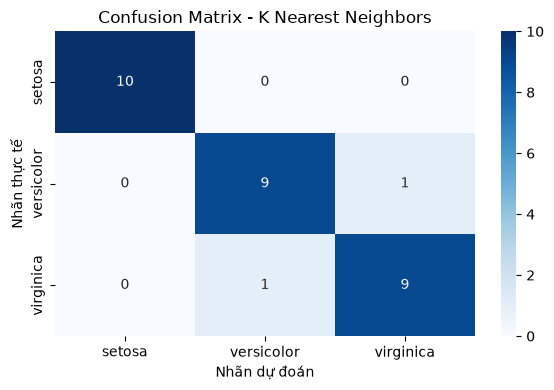

In [22]:
print("NguyenDucTinh - 6451071077")

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

acc_knn = danh_gia_mo_hinh("K Nearest Neighbors", y_test, y_pred_knn)

## Câu h: Phân lớp bằng Neural Network

NguyenDucTinh - 6451071077


c:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333 (1.30 KB)

 Trainable params: 333 (1.30 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 962us/step - accuracy: 0.3500 - loss: 1.0591  
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 788us/step - accuracy: 0.5250 - loss: 0.9801
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 786us/step - accuracy: 0.6750 - loss: 0.8787
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 805us/step - accuracy: 0.7667 - loss: 0.7622
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 846us/step - accuracy: 0.8250 - loss: 0.6462
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 824us/step - accuracy: 0.7583 - loss: 0.5543
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 809us/step - accuracy: 0.8417 - loss: 0.4900 
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 854us/step - accuracy: 0.9167 - loss: 0.4345
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 789us/step - accuracy: 0.9333 - loss: 0.3861
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 787us/step - accuracy: 0.9333 - loss: 0.3577
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 825us/step - accuracy: 0.9417 - loss: 0.3198
Epoch 12/100
120

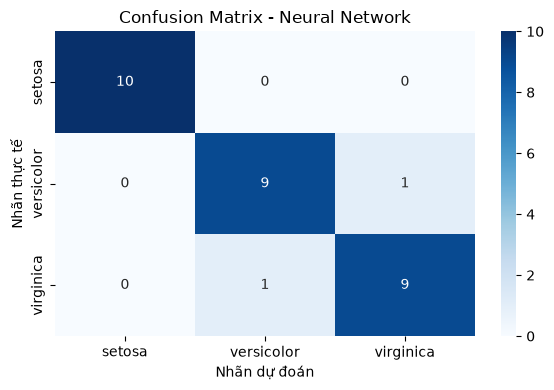

In [23]:
print("NguyenDucTinh - 6451071077")

# Xây dựng Neural Network gồm 2 hidden layers và 1 output layer
nn_model = Sequential()

# Hidden layer 1: 10 neuron, hàm kích hoạt ReLU
nn_model.add(Dense(
    10,
    activation="relu",
    input_shape=(X_train.shape[1],)
))

# Hidden layer 2: 20 neuron, hàm kích hoạt ReLU
nn_model.add(Dense(20, activation="relu"))

# Output layer: 3 neuron tương ứng 3 lớp, hàm Softmax
nn_model.add(Dense(3, activation="softmax"))

# Biên dịch mô hình
nn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Hiển thị cấu trúc mô hình
nn_model.summary()

# Huấn luyện 100 epochs, batch_size = 1
history = nn_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=1,
    verbose=1
)

# Dự đoán xác suất và chọn lớp có xác suất lớn nhất
y_prob_nn = nn_model.predict(X_test)
y_pred_nn = np.argmax(y_prob_nn, axis=1)

acc_nn = danh_gia_mo_hinh("Neural Network", y_test, y_pred_nn)

## Câu i: Dự đoán 3 mẫu dữ liệu mới

In [24]:
print("NguyenDucTinh - 6451071077")

# Ba mẫu dữ liệu mới theo đề bài
X_new = np.array([
    [6.2, 2.9, 4.3, 1.3],
    [5.1, 3.5, 1.4, 0.2],
    [7.3, 2.8, 6.4, 2.1]
])

# Chuẩn hóa bằng giá trị lớn nhất của từng cột trong dữ liệu Iris gốc
X_new = X_new / iris.data.max(axis=0)

# Dự đoán bằng 4 mô hình
pred_dt = dt_model.predict(X_new)
pred_nb = nb_model.predict(X_new)
pred_knn = knn_model.predict(X_new)
pred_nn = np.argmax(nn_model.predict(X_new), axis=1)

models_predictions = {
    "Decision Tree": pred_dt,
    "Naive Bayes": pred_nb,
    "KNN": pred_knn,
    "Neural Network": pred_nn
}

for model_name, predictions in models_predictions.items():
    print("\nMô hình:", model_name)
    for i, prediction in enumerate(predictions):
        print(f"Mẫu {i + 1} => {iris.target_names[prediction]}")

NguyenDucTinh - 6451071077
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step

Mô hình: Decision Tree
Mẫu 1 => versicolor
Mẫu 2 => setosa
Mẫu 3 => virginica

Mô hình: Naive Bayes
Mẫu 1 => versicolor
Mẫu 2 => setosa
Mẫu 3 => virginica

Mô hình: KNN
Mẫu 1 => versicolor
Mẫu 2 => setosa
Mẫu 3 => virginica

Mô hình: Neural Network
Mẫu 1 => versicolor
Mẫu 2 => setosa
Mẫu 3 => virginica


## Câu j: So sánh và nhận xét hiệu suất các mô hình

NguyenDucTinh - 6451071077
Bảng so sánh Accuracy:


,Mô hình,Accuracy
0,Decision Tree,0.933333
1,Naive Bayes,0.966667
2,KNN,0.933333
3,Neural Network,0.933333



Mô hình có Accuracy cao nhất:
Mô hình     Naive Bayes
Accuracy       0.966667
Name: 1, dtype: object


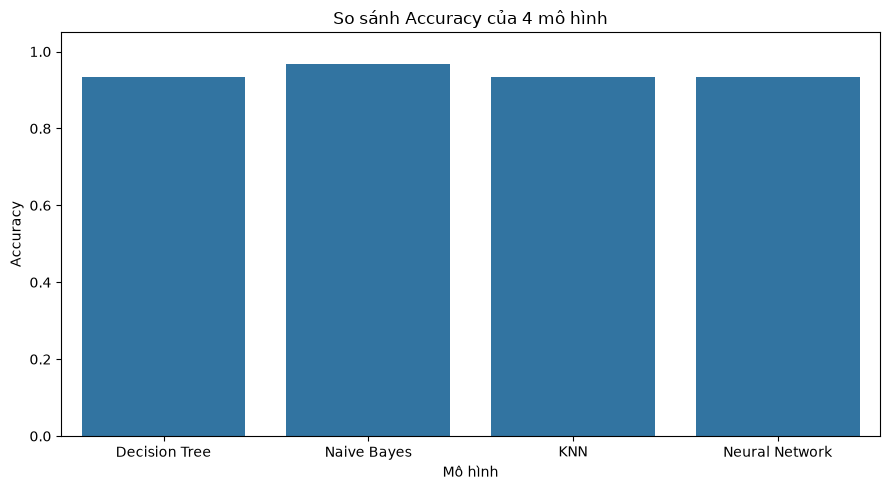

In [25]:
print("NguyenDucTinh - 6451071077")

results = pd.DataFrame({
    "Mô hình": [
        "Decision Tree",
        "Naive Bayes",
        "KNN",
        "Neural Network"
    ],
    "Accuracy": [
        acc_dt,
        acc_nb,
        acc_knn,
        acc_nn
    ]
})

print("Bảng so sánh Accuracy:")
display(results)

best_model = results.loc[results["Accuracy"].idxmax()]
print("\nMô hình có Accuracy cao nhất:")
print(best_model)

plt.figure(figsize=(9, 5))
sns.barplot(data=results, x="Mô hình", y="Accuracy")
plt.title("So sánh Accuracy của 4 mô hình")
plt.ylim(0, 1.05)
plt.xlabel("Mô hình")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()